In [1]:
import numpy as np
import pandas as pd

DATA_PATH = "../../Lab01/2/sp500_yahoo.csv"
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df['Return'] = df['Close'].pct_change()
df['Vol_5d'] = df['Return'].rolling(5).std()
df['MA5_ratio'] = df['Close'] / df['Close'].rolling(5).mean() - 1
df['MA20_ratio'] = df['Close'] / df['Close'].rolling(20).mean() - 1
df['Volume_change'] = df['Volume'].pct_change()

df['Next_Return'] = df['Return'].shift(-1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

df['Target_Binary'] = (df['Next_Return'] > 0).astype(int)

conditions = [
    df['Next_Return'] < -0.005,
    (df['Next_Return'] >= -0.005) & (df['Next_Return'] <= 0.005),
    df['Next_Return'] > 0.005
]
df['Target_Multi'] = np.select(conditions, [0, 1, 2]).astype(int)

feature_cols = ['Return', 'Vol_5d', 'MA5_ratio', 'MA20_ratio', 'Volume_change']
X = df[feature_cols].values
X = (X - X.mean(axis=0)) / X.std(axis=0)

split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_bin_train, y_bin_test = df['Target_Binary'].values[:split_idx], df['Target_Binary'].values[split_idx:]
y_mul_train, y_mul_test = df['Target_Multi'].values[:split_idx], df['Target_Multi'].values[split_idx:]

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (15443, 5), X_test shape: (3861, 5)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

sk_logistic = LogisticRegression(max_iter=1000, random_state=42)
sk_logistic.fit(X_train, y_bin_train)

y_pred_sk_bin = sk_logistic.predict(X_test)
acc_bin = accuracy_score(y_bin_test, y_pred_sk_bin)

print("=" * 65)
print("KẾT QUẢ ĐÁNH GIÁ (YÊU CẦU 3.1 - SCIKIT-LEARN LOGISTIC REGRESSION):")
print(f"Accuracy (Độ chính xác): {acc_bin:.4f}\n")
print(classification_report(y_bin_test, y_pred_sk_bin, target_names=["Giảm/Đứng (0)", "Tăng (1)"]))
print("=" * 65)

KẾT QUẢ ĐÁNH GIÁ (LOGISTIC REGRESSION VỚI CLASS_WEIGHT='BALANCED'):
Accuracy: 0.4890

               precision    recall  f1-score   support

Giảm/Đứng (0)       0.44      0.42      0.43      1766
     Tăng (1)       0.53      0.55      0.54      2095

     accuracy                           0.49      3861
    macro avg       0.48      0.48      0.48      3861
 weighted avg       0.49      0.49      0.49      3861



In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

sk_softmax = LogisticRegression(max_iter=1000, random_state=42)
sk_softmax.fit(X_train, y_mul_train)

y_pred_sk_mul = sk_softmax.predict(X_test)
acc_mul = accuracy_score(y_mul_test, y_pred_sk_mul)

print("=" * 65)
print("KẾT QUẢ ĐÁNH GIÁ (YÊU CẦU 3.2 - SCIKIT-LEARN SOFTMAX REGRESSION):")
print(f"Accuracy (Độ chính xác): {acc_mul:.4f}\n")
print(classification_report(y_mul_test, y_pred_sk_mul, target_names=["Giảm mạnh (0)", "Đi ngang (1)", "Tăng mạnh (2)"]))
print("=" * 65)

KẾT QUẢ ĐÁNH GIÁ (YÊU CẦU 3.2 - SCIKIT-LEARN SOFTMAX REGRESSION):
Accuracy (Độ chính xác): 0.5234

               precision    recall  f1-score   support

Giảm mạnh (0)       0.31      0.08      0.12       822
 Đi ngang (1)       0.54      0.95      0.69      1966
Tăng mạnh (2)       0.41      0.09      0.15      1073

     accuracy                           0.52      3861
    macro avg       0.42      0.37      0.32      3861
 weighted avg       0.46      0.52      0.42      3861



<Figure size 700x600 with 0 Axes>

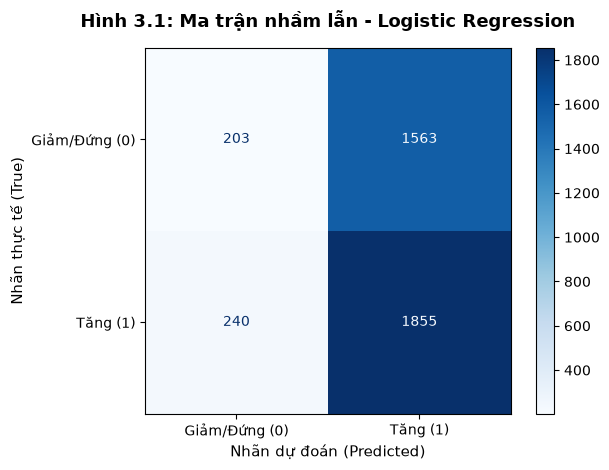

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6), dpi=100)
ConfusionMatrixDisplay.from_predictions(
    y_bin_test, 
    y_pred_sk_bin, 
    display_labels=["Giảm/Đứng (0)", "Tăng (1)"], 
    cmap="Blues",
    colorbar=True
)
plt.title("Hình 3.1: Ma trận nhầm lẫn - Logistic Regression", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Nhãn dự đoán (Predicted)", fontsize=11)
plt.ylabel("Nhãn thực tế (True)", fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()


<Figure size 800x650 with 0 Axes>

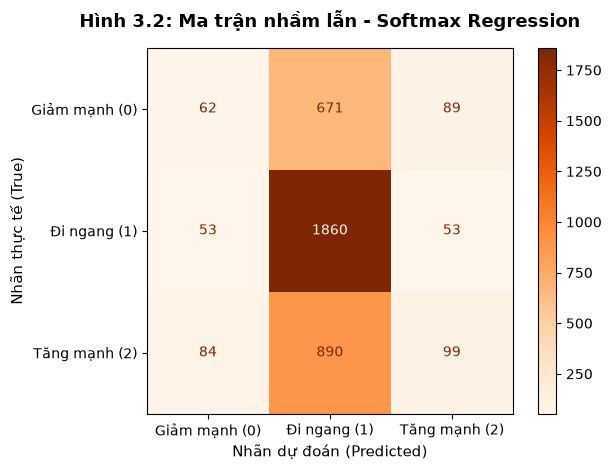

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(8, 6.5), dpi=100)
ConfusionMatrixDisplay.from_predictions(
    y_mul_test, 
    y_pred_sk_mul, 
    display_labels=["Giảm mạnh (0)", "Đi ngang (1)", "Tăng mạnh (2)"], 
    cmap="Oranges",
    colorbar=True
)
plt.title("Hình 3.2: Ma trận nhầm lẫn - Softmax Regression", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Nhãn dự đoán (Predicted)", fontsize=11)
plt.ylabel("Nhãn thực tế (True)", fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()
